<div align="center">

# Classify text with a trained linear head

Train a text classifier, compare its accuracy, and save it for your app.

</div>

## When do you need this?

You want to sort reviews by sentiment or route news by topic.
You need a saved model that predicts labels directly from text in your app.
**Train outside fse**, then import the finished linear head.

## The story in pictures

![The same training texts feed four classifiers. Unseen test texts compare accuracy. Save the fse classifier for your app.](media/02-linear-heads.svg)

A **linear head** is a small trained model that turns vectors into labels or scores.
We compare fse's linear head with a fine-tuned Model2Vec MLP (multilayer perceptron), TF-IDF plus logistic regression, and fastText.
TF-IDF counts words and gives common words less weight, while logistic regression learns how those features predict labels.
fastText learns its own word vectors and classifier from the training texts.

## 1. Load two real datasets

[SST-5](https://huggingface.co/datasets/SetFit/sst5) contains movie reviews with five sentiment labels.
[AG News](https://huggingface.co/datasets/SetFit/ag_news) has four news topics.
We keep their published test splits separate and use a fixed, stratified sample for AG News, keeping each class represented.
The [helper](_helpers.py) pins both dataset revisions, and the [index](README.md#run-a-recipe) covers installation.

In [1]:
from _helpers import Recipe
import fse
import numpy as np

recipe = Recipe()
work = recipe.work

Recipe run: 2026-11-01. Generated files are temporary.
Apple M1 Pro. macOS-27.0.1-arm64-arm-64bit-Mach-O. Python 3.13.16.


Build one shared split for all four methods.
The printed counts show which texts are available for fitting, validation, and testing.

In [2]:
import fse
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 7
datasets = {}
for name in ("SST-5", "AG News"):
    train_texts, train_labels = recipe.dataset(name, "train")
    test_texts, test_labels = recipe.dataset(name, "test")
    if name == "AG News":
        train_texts, _, train_labels, _ = train_test_split(
            train_texts,
            train_labels,
            train_size=8000,
            stratify=train_labels,
            random_state=SEED,
        )
        test_texts, _, test_labels, _ = train_test_split(
            test_texts,
            test_labels,
            train_size=2000,
            stratify=test_labels,
            random_state=SEED,
        )
    fit_x, val_x, fit_y, val_y = train_test_split(
        train_texts,
        train_labels,
        test_size=0.2,
        stratify=train_labels,
        random_state=SEED,
    )
    datasets[name] = (fit_x, fit_y, val_x, val_y, test_texts, test_labels)
    print(name, {"fit": len(fit_x), "validation": len(val_x), "test": len(test_texts)})

/Users/oliverborchers/.herdr/worktrees/Fast_Sentence_Embeddings/dr195-tutorials/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SST-5 {'fit': 6835, 'validation': 1709, 'test': 2210}


AG News {'fit': 6400, 'validation': 1600, 'test': 2000}


## 2. Train the fse head

POTION-base-8M supplies the vectors for a scikit-learn logistic regression head.
**Every method sees the same fit and test texts**, with validation texts reserved for Model2Vec's early stopping.
We use fixed settings rather than tune on test results.
POTION vectors have unit length here, so fse keeps that normalization when running the head.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

encoder = recipe.encoder()
results = []
classifiers = {}


def record(dataset, method, expected, predicted):
    results.append(
        {
            "dataset": dataset,
            "method": method,
            "accuracy": float(accuracy_score(expected, predicted)),
            "macro_f1": float(f1_score(expected, predicted, average="macro")),
        }
    )


for name, (fit_x, fit_y, val_x, val_y, test_x, test_y) in datasets.items():
    train_rows = encoder.encode(fit_x, workers=1)
    test_rows = encoder.encode(test_x, workers=1)
    head = LogisticRegression(C=1, max_iter=1000, random_state=SEED).fit(train_rows, fit_y)
    classifier = fse.Classifier.from_sklearn(encoder, head)
    predicted = classifier.predict(test_x, workers=1)
    np.testing.assert_array_equal(predicted, head.predict(test_rows))
    np.testing.assert_allclose(
        classifier.predict_proba(test_x, workers=1),
        head.predict_proba(test_rows),
        atol=3e-6,
    )
    classifiers[name] = classifier
    record(name, "fse + linear head", test_y, predicted)

## 3. Train the word-count baseline

A **baseline** is a simple method used as a comparison.
TF-IDF learns its vocabulary on fit texts only, including adjacent word pairs.
It never sees test texts while fitting.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline

for name, (fit_x, fit_y, val_x, val_y, test_x, test_y) in datasets.items():
    baseline = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000),
        LogisticRegression(C=1, max_iter=1000, random_state=SEED),
    )
    baseline.fit(fit_x, fit_y)
    record(name, "TF-IDF + logistic regression", test_y, baseline.predict(test_x))

## 4. Train Model2Vec's MLP classifier

An MLP, or multilayer perceptron, is a neural network with a hidden layer between input vectors and output scores.
[Model2Vec 0.10.0](https://github.com/MinishLab/model2vec/blob/v0.10.0/model2vec/train/classifier.py) trains this head with PyTorch and fine-tunes the POTION word vectors.
Its default head, also used here, has one hidden layer of 512 units with ReLU, which replaces negative hidden values with zero.
**fse's head is linear**, with no hidden layer.


The [deployment head runs in plain NumPy](https://github.com/MinishLab/model2vec/blob/v0.10.0/model2vec/inference/mlp.py).
It uses softmax for single-label probabilities or sigmoid for multilabel probabilities, where several labels can apply.
This recipe records accuracy using the training model's PyTorch `predict` method, without exporting its NumPy pipeline.
Training uses at most 10 epochs, passes through the fit texts, with early stopping after three checks without a validation gain.

Training progress goes to a temporary text log.
The comparison table below keeps the final quality scores visible.

In [5]:
from contextlib import redirect_stderr, redirect_stdout
import torch
from model2vec import StaticModel
from model2vec.train import StaticModelForClassification

torch.set_num_threads(1)
for name, (fit_x, fit_y, val_x, val_y, test_x, test_y) in datasets.items():
    base = StaticModel.from_pretrained(recipe.model_folder())
    model = StaticModelForClassification.from_static_model(
        model=base,
        n_layers=1,
        hidden_dim=512,
        freeze=False,
        normalize=True,
    )
    log_path = work / (name.replace(" ", "-") + "-training.log")
    with log_path.open("w") as log, redirect_stdout(log), redirect_stderr(log):
        model.fit(
            fit_x,
            fit_y.tolist(),
            X_val=val_x,
            y_val=val_y.tolist(),
            device="cpu",
            batch_size=128,
            learning_rate=1e-3,
            max_epochs=10,
            early_stopping_patience=3,
            random_seed=SEED,
        )
    record(name, "Model2Vec classifier (fine-tuned)", test_y, model.predict(test_x))
    print(name, "training finished. Progress log:", log_path.name)


SST-5 training finished. Progress log: SST-5-training.log


AG News training finished. Progress log: AG-News-training.log


## 5. Train fastText

The pinned fastText 0.9.3 builds on Python 3.13 for this run.
Its **supervised classifier** learns from the same fit texts, without pretrained POTION vectors.
We use word pairs, 100 dimensions, 25 epochs, and one thread with a fixed seed.

In [6]:
import fasttext

for name, (fit_x, fit_y, val_x, val_y, test_x, test_y) in datasets.items():
    training_file = work / (name.replace(" ", "-") + ".txt")
    training_file.write_text(
        "\n".join(
            f"__label__{label} " + " ".join(text.split())
            for text, label in zip(fit_x, fit_y, strict=True)
        )
        + "\n",
        encoding="utf-8",
    )
    fast = fasttext.train_supervised(
        input=str(training_file),
        dim=100,
        wordNgrams=2,
        epoch=25,
        lr=0.5,
        bucket=100000,
        minCount=1,
        loss="softmax",
        thread=1,
        seed=SEED,
        verbose=0,
    )
    labels, _ = fast.predict([" ".join(t.split()) for t in test_x], k=1)
    predicted = [int(row[0].removeprefix("__label__")) for row in labels]
    record(name, "fastText", test_y, predicted)

## Result: compare quality on unseen texts

**Macro-F1 gives every class equal weight**, even when some sentiment classes have fewer examples.
Accuracy is the fraction of correct labels, and both scores range from zero to one.
Use macro-F1 as the main SST-5 comparison and accuracy for the balanced AG News sample.
These are single fixed-seed runs with limited training settings, rather than a general ranking.

**Table and chart: a fine-tuned Model2Vec MLP versus fse's linear head**, with TF-IDF and fastText baselines.
Model2Vec uses a 512-unit ReLU hidden layer and fine-tunes its word vectors in PyTorch, while fse keeps the POTION vectors fixed.
The [Model2Vec deployment head](https://github.com/MinishLab/model2vec/blob/v0.10.0/model2vec/inference/mlp.py) runs in plain NumPy with softmax or sigmoid output probabilities.
These recorded accuracy scores use the training model's PyTorch predictions, so this is not an inference-speed comparison.

Matplotlib is building the font cache; this may take a moment.


| Dataset | Method | Accuracy | Macro-F1 |
|---|---|---:|---:|
| SST-5 | fse + linear head | 0.4005 | 0.3708 |
| AG News | fse + linear head | 0.8780 | 0.8777 |
| SST-5 | TF-IDF + logistic regression | 0.3900 | 0.3209 |
| AG News | TF-IDF + logistic regression | 0.8750 | 0.8746 |
| SST-5 | Model2Vec classifier (fine-tuned) | 0.4213 | 0.3770 |
| AG News | Model2Vec classifier (fine-tuned) | 0.8805 | 0.8803 |
| SST-5 | fastText | 0.3891 | 0.3721 |
| AG News | fastText | 0.8550 | 0.8545 |

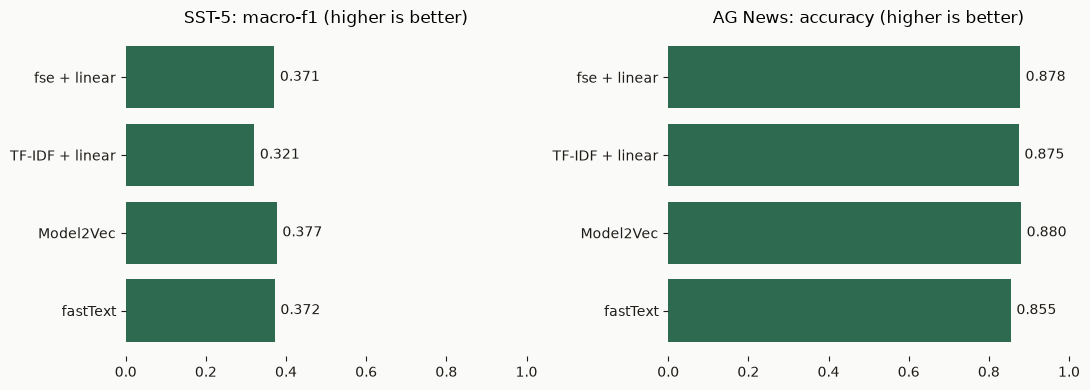

1110

In [7]:
import json
from IPython.display import Markdown, display
from _charts import quality_chart

display(
    Markdown(
        "| Dataset | Method | Accuracy | Macro-F1 |\n|---|---|---:|---:|\n"
        + "\n".join(
            f"| {r['dataset']} | {r['method']} | {r['accuracy']:.4f} | {r['macro_f1']:.4f} |"
            for r in results
        )
    )
)
quality_chart(results)
(work / "accuracy.json").write_text(json.dumps(results, indent=2))

## 6. Save a finished classifier

The saved classifier includes its encoder, so your app can **load it without scikit-learn**.
Because this head uses unit-length vectors, save the complete model with the default settings.
`standalone=True` folds a head into word rows and only works for heads trained on raw means.
The assertion checks that saving and loading preserve the test predictions.

In [8]:
classifier = classifiers["AG News"]
path = work / "news-classifier.safetensors"
classifier.save(path)
loaded = fse.Classifier.load(path)
test_x = datasets["AG News"][4]
np.testing.assert_array_equal(
    loaded.predict(test_x, workers=1), classifier.predict(test_x, workers=1)
)
topic_names = ["World", "Sports", "Business", "Science and technology"]
expected = datasets["AG News"][5]
for text, predicted, actual in zip(test_x[:5], loaded.predict(test_x[:5], workers=1), expected[:5], strict=True):
    print(f"Predicted: {topic_names[int(predicted)]}. Expected: {topic_names[int(actual)]}.")
    print(text[:160] + "\n")


Predicted: Business. Expected: Business.
Heineken Profit Dips But Repeats Outlook  AMSTERDAM (Reuters) - Dutch brewer Heineken posted a 4.5  percent fall in core profit for the first half on Wednesday,

Predicted: World. Expected: World.
The radical Islamic cleric was deported from Germany late Tuesday &lt;b&gt;...&lt;/b&gt; Turkish officials were doing what was necessary in regard to the return

Predicted: Science and technology. Expected: Sports.
Hamm should support Yang Paul Hamm needs a new marketing strategy. Either that, or he needs a clue. One harmless gesture separates him from lionization in Ameri

Predicted: Sports. Expected: Sports.
Despite struggles at plate, Boone wins Gold Glove The way Bret Boone sees it, winning a Gold Glove after a tough offensive season is a validation of the award i

Predicted: Science and technology. Expected: Science and technology.
Microsoft Fixes Key SP2 Issue (NewsFactor) NewsFactor - Microsoft (Nasdaq: MSFT) has released a Windows XP Service Pa

## Optional: predict a score instead of a label

A regression head predicts numbers.
For this example, we treat SST-5 labels 0 through 4 as equally spaced sentiment scores, which is an **explicit modeling assumption**.
Mean absolute error, or MAE, measures the average error in those label units.

In [9]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

fit_x, fit_y, _, _, test_x, test_y = datasets["SST-5"]
regression = Ridge(alpha=1).fit(encoder.encode(fit_x, workers=1), fit_y.astype(float))
regressor = fse.Regressor.from_sklearn(encoder, regression)
predicted = regressor.predict(test_x, workers=1)
np.testing.assert_allclose(
    predicted, regression.predict(encoder.encode(test_x, workers=1)), atol=3e-5
)
regressor.save(work / "sentiment-score.safetensors")
print("MAE:", round(mean_absolute_error(test_y, predicted), 4))
print(
    "Training-mean baseline MAE:",
    round(mean_absolute_error(test_y, np.full(len(test_y), fit_y.mean())), 4),
)

MAE: 0.8501
Training-mean baseline MAE: 1.141


## What next?

- [Process a file in batches](03-files-with-resume.ipynb).
- [fse API and design](../docs/architecture/formats.md)
- [scikit-learn linear models](https://scikit-learn.org/stable/modules/linear_model.html), [fastText classification](https://fasttext.cc/docs/en/supervised-tutorial.html)

Back to the [recipe index](README.md) or the [main README](../README.md).

## Clean up

The helper keeps generated files in a temporary folder. Run this after you finish exploring the results.

In [10]:
recipe.close()